## Resumen de la revisión v2 <a class="tocSkip"></a>

----

# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

Escribe aquí tu plan de solución para el Paso 1. Descripción de los datos.

Para la carga de archivos utilizo "pd.red_csv" dentro del cual añado el separador con "sep=';'" siendo que así viene el formato desde el csv.
Realizo la carga de forma individual para cada DataSet, añadiendo show_counts=True, porque de esa forma siendo un dataset muy grande se cuentan todas las filas sin importar el tamaño del archivo.

In [1]:
import pandas as pd
import numpy as np# importar librerías

In [2]:
df_orders = pd.read_csv ("/datasets/instacart_orders.csv", sep=";") 
df_products = pd.read_csv ("/datasets/products.csv", sep=";") # leer conjuntos de datos en los DataFrames
df_aisles = pd.read_csv ("/datasets/aisles.csv", sep=";") 
df_departments = pd.read_csv ("/datasets/departments.csv", sep=";") 
df_order_products = pd.read_csv ("/datasets/order_products.csv", sep=";") 

In [3]:
df_orders.info(show_counts=True) # mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [4]:
df_products.info(show_counts=True) # mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [5]:
df_aisles.info(show_counts=True) # mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [6]:
df_departments.info(show_counts=True) # mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes


In [7]:
df_order_products.info(show_counts=True) # mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusiones
En df_orders:
days_since_prior_order con atributo float64, tiene una diferencia de 28,819 filas no-nulas faltantes al solo contar con 450,148 filas respecto a 478,967 de las demás columnas
order_id, user_id, order_number, order_dow, order_hour_of_day tienen 478,967 filas non-null con atributo int64  

En df_products:
product_name con atributo object, tiene una diferencia de 1,258 filas no-nulas faltantes al solo contar con 48,436 filas respecto a 49,694 de las demás columnas
 product_id, aisle_id, department_id tienen 49,694 filas non-null con atributo int64 

df_aisles:
Cuenta con 2 columnas aisle_id, aisle. Ambas con 134 non-null filas.
Donde aisle_id es de atributo int64 y aisle es de atributo object.

df_departments:
Cuenta con 2 columnas department_id y department. Ambas con 21 non-null filas.
Donde department_id es de atributo int64 y department es de atributo object.

df_order_products:
add_to_cart_order con atributo float64, tiene una diferencia de 836 filas no-nulas faltantes al solo contar con 4,544,171 filas respecto a 4,545,007 de las demás columnas
order_id, user_id, product_id, reordered tienen 4,545,007 filas non-null con atributo int64  

# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Escribe aquí tu plan para el Paso 2. Preprocesamiento de los datos.

Para revisar los duplicados en cada DataSet se utiliza el comando .duplicated() al cual se le añade .sum() para sumar la cantidad de duplicados en cada DataSet
Al entrar al dataset con df[df.duplicated()] se imprimen las filas con duplicados y no solamente la cantidad, dentro de cada DataSet.

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [8]:
# Revisa si hay pedidos duplicados
# Duplicados en df_orders
print(df_orders.duplicated().sum())
print(df_orders[df_orders.duplicated()])
print()

# Duplicados en df_products
print(df_products.duplicated().sum())
print(df_products[df_products.duplicated()])
print()

# Duplicados en df_aisles
print(df_aisles.duplicated().sum())
print(df_aisles[df_aisles.duplicated()])
print()

# Duplicados en df_departments
print(df_departments.duplicated().sum())
print(df_departments[df_departments.duplicated()])
print()

# Duplicados en df_order_products
print(df_order_products.duplicated().sum())
print(df_order_products[df_order_products.duplicated()])

15
        order_id  user_id  order_number  order_dow  order_hour_of_day  \
145574    794638    50898            24          3                  2   
223105   2160484   107525            16          3                  2   
230807   1918001   188546            14          3                  2   
266232   1782114   106752             1          3                  2   
273805   1112182   202304            84          3                  2   
284038   2845099    31189            11          3                  2   
311713   1021560    53767             3          3                  2   
321100    408114    68324             4          3                  2   
323900   1919531   191501            32          3                  2   
345917   2232988    82565             1          3                  2   
371905    391768    57671            19          3                  2   
394347    467134    63189            21          3                  2   
411408   1286742   183220            48         

¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?
Si, al parecer todas las líneas duplicadas que aparecen en df_orders fueron órdenes realizadas el miércoles a las 2:00 am. 
Lo que equivale a 15 filas duplicadas.


In [9]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
pedidos_miercoles_2am = df_orders[(df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)]
display(pedidos_miercoles_2am)

# Aquí se muestran las 30 filas que al ser duplicadas son 15 duplicados.
duplicados_especificos = pedidos_miercoles_2am[pedidos_miercoles_2am['order_id'].duplicated(keep=False)]
display(duplicados_especificos.sort_values(by='order_id'))

# Aquí se muestran los pedidos únicos del miércoles a las 2:00 am. Que equivalen a 106 filas no duplicadas.
print()
print(pedidos_miercoles_2am['order_id'].nunique())

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
394347,467134,63189,21,3,2,2.0
250626,467134,63189,21,3,2,2.0
99462,794638,50898,24,3,2,2.0
145574,794638,50898,24,3,2,2.0
311713,1021560,53767,3,3,2,9.0
242618,1021560,53767,3,3,2,9.0



106


¿Qué sugiere este resultado?
1. En el segmento de Miércoles a las 2:00AM hay 121 filas.
2. Las filas duplicadas en todas las columnas son 15.
3. Con el comando .nunique() se muestra que quedan solamente 106 resultados realmente únicos dentro del mismo horario y fecha del miércoles a las 2:00 am.

In [10]:
# Elimina los pedidos duplicados
# Eliminamos duplicados en todo el dataset original
df_orders = df_orders.drop_duplicates().reset_index(drop=True)

In [11]:
# Vuelve a verificar si hay filas duplicadas
# Verificamos si en el horario conflictivo ahora todo está bien
print(df_orders[(df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)].shape[0])

106


In [12]:
# Vuelve a verificar únicamente si hay IDs duplicados de pedidos
# Verificación de IDs duplicados en la columna order_id
duplicados_final = df_orders['order_id'].duplicated().sum()

print(f"Número de IDs de pedido duplicados: {duplicados_final}")

# Verificación específica para el grupo del miércoles a las 2:00 a.m.
check_horario = df_orders[(df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)]
print(f"Filas restantes el miércoles a las 2 a.m.: {len(check_horario)}")

Número de IDs de pedido duplicados: 0
Filas restantes el miércoles a las 2 a.m.: 106


Describe brevemente tus hallazgos y lo que hiciste con ellos

Se eliminaron un total de 15 filas duplicadas de la tabla completa "df_orders", respecto al bloque de horario de Miércoles a las 2:00AM.
Dentro del subconjunto de pedidos realizados los miércoles a las 2:00AM, la cantidad de registros pasó de 121 a 106, eliminando los duplicados que existían en ese horario.

### `products` data frame

In [13]:
# Verifica si hay filas totalmente duplicadas
print(df_products.duplicated().sum())

0


In [14]:
# Revisa únicamente si hay ID de productos duplicados
print(df_products['product_id'].duplicated().sum())

0


In [15]:
df_products['product_name'] = df_products['product_name'].str.lower()
print(df_products['product_name'].duplicated().sum())
print(df_products['product_name'].head(20))
print()
print("Se han cambiado todos los nombres a minúsculas, para evitar duplicados.")

1361
0                            chocolate sandwich cookies
1                                      all-seasons salt
2                  robust golden unsweetened oolong tea
3     smart ones classic favorites mini rigatoni wit...
4                             green chile anytime sauce
5                                          dry nose oil
6                        pure coconut water with orange
7                     cut russet potatoes steam n' mash
8                     light strawberry blueberry yogurt
9        sparkling orange juice & prickly pear beverage
10                                    peach mango juice
11                           chocolate fudge layer cake
12                                    saline nasal mist
13                       fresh scent dishwasher cleaner
14                             overnight diapers size 6
15                        mint chocolate flavored syrup
16                                    rendered duck fat
17                  pizza for one suprema  

In [16]:
# Se eliminan los duplicados físicamente del DataFrame
df_products = df_products.drop_duplicates(subset=['product_name']).reset_index(drop=True)

# Comprobación que ahora hay 0 duplicados
print(f"Duplicados restantes: {df_products['product_name'].duplicated().sum()}")

Duplicados restantes: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

See borran los duplicados de la siguiente forma.
df_products = df_products.drop_duplicates(subset=['product_name']).reset_index(drop=True).
Y de ésta forma se comprueba que la suma de duplicados ya sea 0.
df_products['product_name'].duplicated().sum())

### `departments` data frame

In [17]:
# Revisa si hay filas totalmente duplicadas
print(df_departments.duplicated().sum())

0


In [18]:
# Revisa únicamente si hay IDs duplicadas de departamentos
print(df_departments['department_id'].duplicated().sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
No encontré filas duplicadas ni IDs de departamento repetidos (ambos resultados fueron 0)
Ésto indica que el catálogo de departamentos es íntegro y cada categoría está correctamente identificada de forma única.
No fué necesario realizar ninguna acción de limpieza en éste DataFrame.

### `aisles` data frame

In [19]:
# Revisa si hay filas totalmente duplicadas
print(df_aisles.duplicated().sum())

0


In [20]:
# Revisa únicamente si hay IDs duplicadas de pasillos
print(df_aisles['aisle_id'].duplicated().sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
Al iguall que en el catálogo de departamentos, no se detectaron filas duplicadas ni IDs de pasillo repetidos. 
Ésto confirma que la estructura de categorías de la tienda está bien organizada y cada pasillo tiene un identificador único asignado, 
por lo que no se requirieron acciones de limpieza adicionales.

### `order_products` data frame

In [21]:
# Revisa si hay filas totalmente duplicadas
print(df_order_products.duplicated().sum())

0


In [22]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso
print(df_order_products.duplicated(subset=['order_id', 'product_id']).sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
No se encontraron filas totalmente duplicadas en el conjunto de datos.
Se realizó una verificación entre order_id y product_id para asegurar que un mismo producto no estuviera registrado más de una vez
dentro de un mismo pedido, obteniendo también un resultado de 0.
Ésto confirma que la relación entre los productos y las órdenes es limpia y está lista para el análisis de frecuencia y asociación.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [23]:
# Encuentra los valores ausentes en la columna 'product_name'
print(df_products['product_name'].isna().sum())

1


Describe brevemente cuáles son tus hallazgos.
La columna "product_name" tiene 1,258 valores ausentes.

In [24]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?
nulos_pasillo_100 = df_products[df_products['product_name'].isna()]
print(nulos_pasillo_100['aisle_id'].unique())

[100]


Describe brevemente cuáles son tus hallazgos.
Si, todos los nombres de productos ausentes están relacionados con el pasillo con ID 100.
Porque todos están ahí, en el pasillo [100] al ser el resiltado de imprimir los valores nulos.

In [25]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
print(nulos_pasillo_100['department_id'].unique())

[21]


Describe brevemente cuáles son tus hallazgos.
Si, todos los nombres de productos ausentes están relacionados con el departamento con ID 21. 
Porque todos están ahí, en el pasillo [21] al ser el resiltado de imprimir los valores nulos.

In [26]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
display(df_aisles[df_aisles['aisle_id'] == 100])
display(df_departments[df_departments['department_id'] == 21])

,aisle_id,aisle
99,100,missing


,department_id,department
20,21,missing


Describe brevemente cuáles son tus hallazgos.
Los datos del pasillo con ID 100 y el departamento con ID 21, muestran el valore "missing" porque los productos ahí no tienen nombre.

In [27]:
# Completa los nombres de productos ausentes con 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')
print(df_products['product_name'].isna().sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
Se identificó que existen valores ausentes en la columna "product_name". 
Al investigar, se descubrió que todos estos productos pertenecen al pasillo 100 y al departamento 21, los cuales están etiquetados como "missing". 
Esto sugiere que son productos no categorizados. Para mantener la integridad del dataset, se reemplazaron los valores nulos por la etiqueta "Unknown".

### `orders` data frame

In [28]:
# Encuentra los valores ausentes
print(df_orders.isna().sum())

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64


In [29]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?
nulos_orders = df_orders[df_orders['days_since_prior_order'].isna()]
print(nulos_orders[nulos_orders['order_number'] != 1])

Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


Describe brevemente tus hallazgos y lo que hiciste con ellos.
Se identificaron un total de 28,817 valores ausentes únicamente en la columna days_since_prior_order.
Las demás columnas no tienen valores ausentes.
Los nulos coinciden exactamente con los pedidos número 1 de los clientes.
Decidí dejar los valores así porque son datos correctos.

### `order_products` data frame

In [30]:
# Encuentra los valores ausentes
print(df_order_products.isna().sum())

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


In [31]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
print(f"Mínimo: {df_order_products['add_to_cart_order'].min()}")
print(f"Máximo: {df_order_products['add_to_cart_order'].max()}")

Mínimo: 1.0
Máximo: 64.0


Describe brevemente cuáles son tus hallazgos.
Se identificaron 836 valores ausentes en la columna add_to_cart_order.
Un dato clave es que el valor máximo registrado en ésta columna es 64.
Se observa que los valores nulos aparecen únicamente en pedidos que tienen una gran cantidad de artículos.
Existe una limitación técnica donde el sistema solo registra la posición del producto en el carrito hasta el artículo número 64. 
Cualquier producto añadido después, del 65 en adelante, aparece como valor ausente.

In [32]:
# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
orders_with_nans = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id'].unique()

In [33]:
# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.
check_64 = df_order_products[df_order_products['order_id'].isin(orders_with_nans)].groupby('order_id')['product_id'].count()
print(f"Mínimo de productos en pedidos con nulos: {check_64.min()}")

Mínimo de productos en pedidos con nulos: 65


Describe brevemente cuáles son tus hallazgos.

Todos los pedidos que presentan valores ausentes en la columna add_to_cart_order tienen un conteo total de al menos 65 artículos.
Existe un límite técnico en el registro del sistema, donde solo se guardaba la secuencia de los primeros 64 productos añadidos al carrito.
Por lo tanto, cualquier producto añadido a partir de la posición 65, el valor no se registra, resultando en un dato ausente (NaN).

In [34]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.

# Llenamos nulos con 999 y convertimos el tipo de dato
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype(int)

# Verificamos el cambio
print(df_order_products['add_to_cart_order'].isna().sum())
print(df_order_products['add_to_cart_order'].dtype)

0
int64


Describe brevemente tus hallazgos y lo que hiciste con ellos.
Se confirmó la hipótesis sobre los valores ausentes:
Al agrupar los pedidos con datos faltantes, el número mínimo de productos por pedido resultó ser 65. 
Esto valida que la columna add_to_cart_order tiene un límite técnico de registro de 64 posiciones.
Los 836 valores ausentes corresponden exclusivamente a productos que fueron agregados al carrito en la posición 65 o superior.

## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 2. Preprocesamiento de los datos

Se eliminaron 15 pedidos duplicados críticos que afectaban el conteo real de transacciones. Asimismo, se validó que los valores ausentes en la frecuencia de compra corresponden exclusivamente a los primeros pedidos de nuevos clientes, por lo que se mantuvieron como información legítima.

Se identificaron 1,361 nombres de productos duplicados. Mediante la conversión a minúsculas, logramos desdenmascarar 104 casos que estaban ocultos por errores de capitalización al estar mezclados mayúsculas con minúsculas en los nombres.
Además, los productos con nombres faltantes se categorizaron como "Unknown", tras descubrir que pertenecían a departamentos y pasillos etiquetados como "missing".

El sistema tiene un límite de registro de 64 productos por carrito. Los 836 valores ausentes encontrados en la posición del carrito fueron imputados con el valor 999, 
permitiendo transformar la columna a tipo entero y asegurar que ningún artículo quede fuera del análisis por limitaciones técnicas.

Se verificó que las tablas de pasillos "aisles" y departamentos "departments" están 100% libres de duplicados y errores, sirviendo como bases maestras sólidas para los cruces de información.

Los datos ahora son consistentes, no presentan redundancias que sesguen los promedios y todos los tipos de datos son los adecuados para iniciar la fase de análisis estadístico y visualización.

# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [35]:
# Verificación de valores para la hora del día (0-23)
print("Rango de horas:", df_orders['order_hour_of_day'].min(), "-", df_orders['order_hour_of_day'].max())

# Verificación de valores para el día de la semana (0-6)
print("Rango de días:", df_orders['order_dow'].min(), "-", df_orders['order_dow'].max())

Rango de horas: 0 - 23
Rango de días: 0 - 6


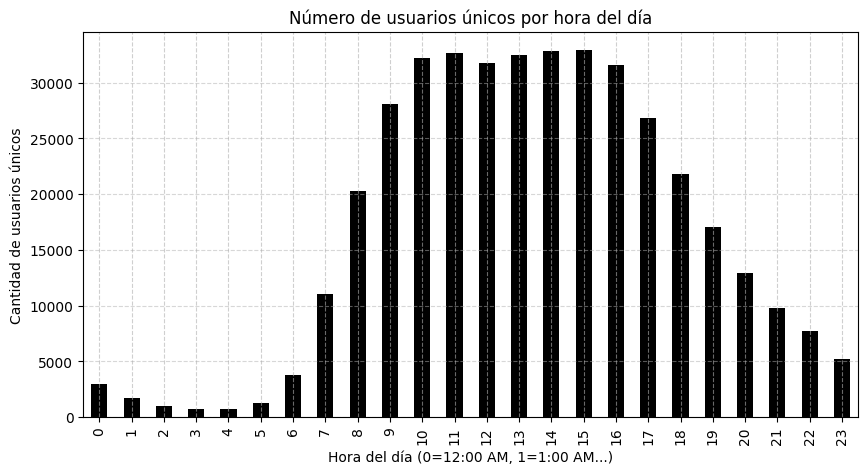

In [36]:
import matplotlib.pyplot as plt

usuarios_por_hora = df_orders.groupby('order_hour_of_day')['user_id'].nunique()

# Graficamos
usuarios_por_hora.plot(
    kind='bar',
    title='Número de usuarios únicos por hora del día',
    xlabel='Hora del día (0=12:00 AM, 1=1:00 AM...)',
    ylabel='Cantidad de usuarios únicos',
    figsize=(10, 5),
    color='black'
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

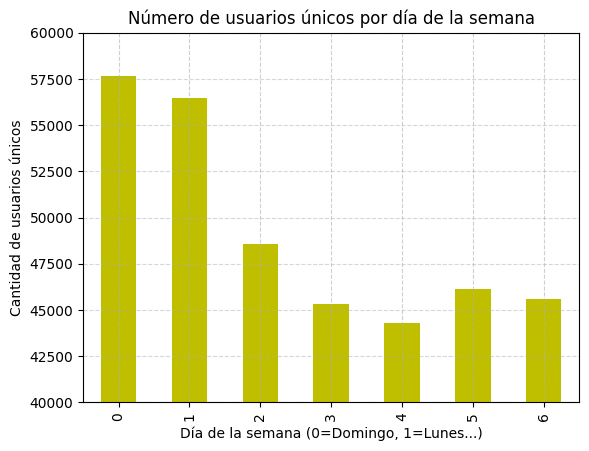

In [37]:
usuarios_por_dia = df_orders.groupby('order_dow')['user_id'].nunique()

# Graficamos
usuarios_por_dia.plot(
    kind='bar',
    title='Número de usuarios únicos por día de la semana',
    xlabel='Día de la semana (0=Domingo, 1=Lunes...)',
    ylabel='Cantidad de usuarios únicos',
    color='y'
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.ylim(40000, 60000)
plt.show()

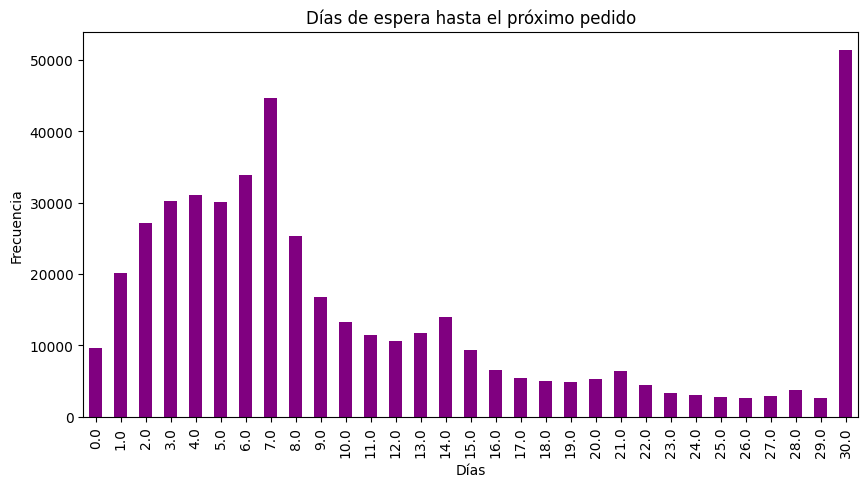

In [38]:
df_orders['days_since_prior_order'].value_counts().sort_index().plot(
    kind='bar', 
    title='Días de espera hasta el próximo pedido',
    xlabel='Días',
    ylabel='Frecuencia',
    figsize=(10, 5),
    color='purple'
)
plt.show()

Escribe aquí tus conclusiones
1) order_hour_of_day: Los valores están correctamente dentro del rango 0-23
No hay horas negativas o superiores a 24.

order_dow: Los valores oscilan entre 0 y 6, cumpliendo con la estructura de una semana estándar donde 0=Domingo, 1=Lunes, 2=Martes, 3=Miércoles, 4=Jueves, 5=Viernes, 6=Sábado

2) Los horarios con mayor actividad
La hora pico, cuando surge la mayor concentración de pedidos ocurre entre las 10:00 AM y las 4:00 PM.
Es el horario donde los servidores y el personal de reparto tendrían más carga.

La actividad cae drásticamente a partir de las 11:00PM y alcanza su punto más bajo entre la 1:00AM y las 5:00AM

3) Los días fuertes son los días 0 y 1, generalmente Domingo y Lunes, muestran los volúmenes más altos de compras.
Los días más calmados son a mitad de la semana, miércoles y jueves, la actividad tiende a estabilizarse o bajar ligeramente.

4) days_since_prior_order: es el que revela más sobre el hábito de consumo
Hay un salto notable en el día 7. Esto confirma que una gran parte de los usuarios tiene un hábito semanal estricto.
El día 30 la barra es muy alta, por lo que algunas personas tardan 30 días o más en volver a comprar o ya no compran.

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

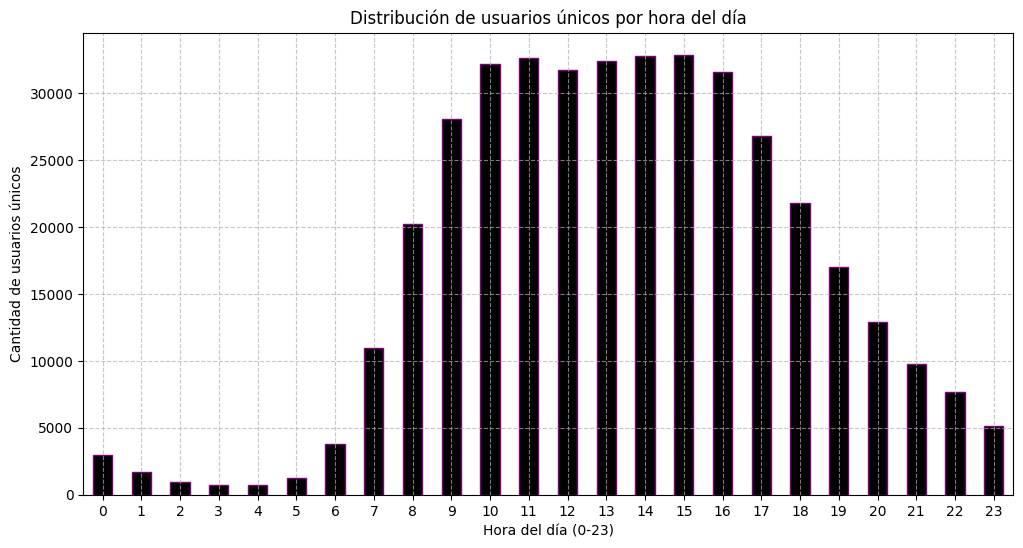

In [39]:
usuarios_por_hora = df_orders.groupby('order_hour_of_day')['user_id'].nunique()

# Graficamos según lo solicitado
plt.figure(figsize=(12, 6))
usuarios_por_hora.plot(kind='bar', color='black', edgecolor='purple')

plt.title('Distribución de usuarios únicos por hora del día')
plt.xlabel('Hora del día (0-23)')
plt.ylabel('Cantidad de usuarios únicos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Escribe aquí tus conclusiones
Las horas en las que más pedidos se realizan son de las 10:00Hrs a las 16:00Hrs con más de 30,000 usuarios únicos. 
Las 10:00AM es el horario más concurrido en el que realizan pedidos los clientes.
Y las horas con menos actividad se conforman entre las 00:00Hrs y las 6:00Hrs, que equivale a menos de 5,000 usuarios. 

### [A3] ¿Qué día de la semana compran víveres las personas?

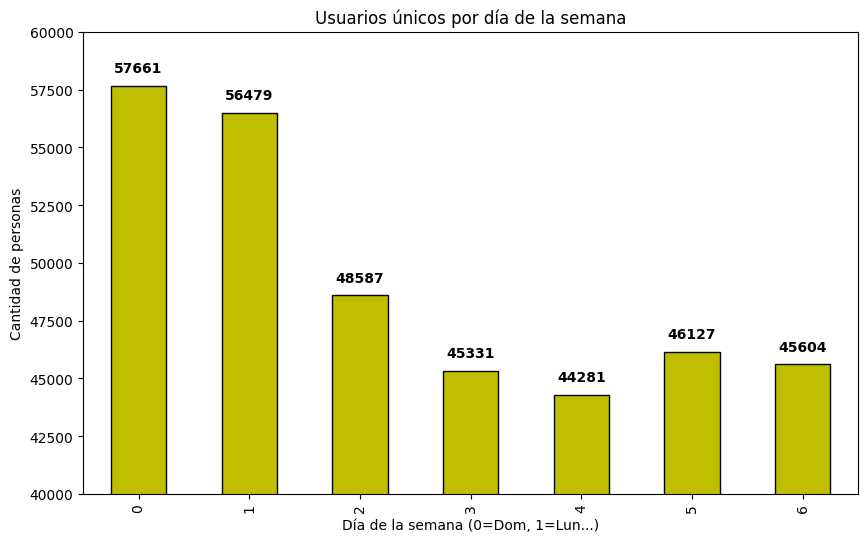

In [40]:
import matplotlib.pyplot as plt

# Agrupar por usuarios únicos
usuarios_por_dia = df_orders.groupby('order_dow')['user_id'].nunique()

# El gráfico
plt.figure(figsize=(10, 6))
barras = usuarios_por_dia.plot(kind='bar', color='y', edgecolor='black')

# Etiquetas
for i, v in enumerate(usuarios_por_dia):
    plt.text(i, v + 600, str(v), ha='center', fontweight='bold')

# Ajuste de rango
plt.ylim(40000, 60000)

plt.title('Usuarios únicos por día de la semana')
plt.xlabel('Día de la semana (0=Dom, 1=Lun...)')
plt.ylabel('Cantidad de personas')

plt.show()

Escribe aquí tus conclusiones
Domingo y Lunes son los días con más pedidos por día.
Siendo el Jueves el día que menor cantidad de pedidos realizan los clientes.

### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

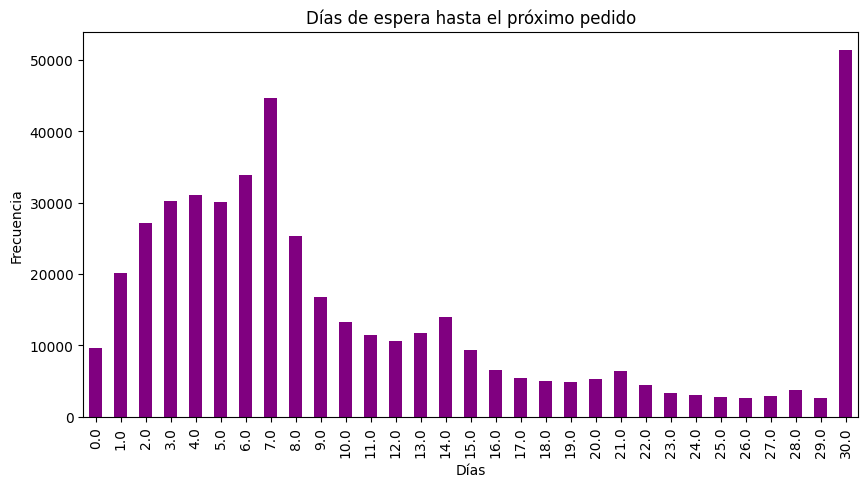

In [41]:
t= df_orders['days_since_prior_order'].value_counts().sort_index().plot(
    kind='bar', 
    title='Días de espera hasta el próximo pedido',
    xlabel='Días',
    ylabel='Frecuencia',
    figsize=(10, 5),
    color='purple'
)

plt.show()

Escribe aquí tus conclusiones

Los valores varían entre 0 pedidos el mismo día y 30 días en realizar un pedido, lo cual es el límite de registro del sistema.
Se identificaron valores ausentes que corresponden estrictamente al primer pedido de cada usuario, por lo que se mantuvieron como nulos para no sesgar el promedio de recurrencia.

# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

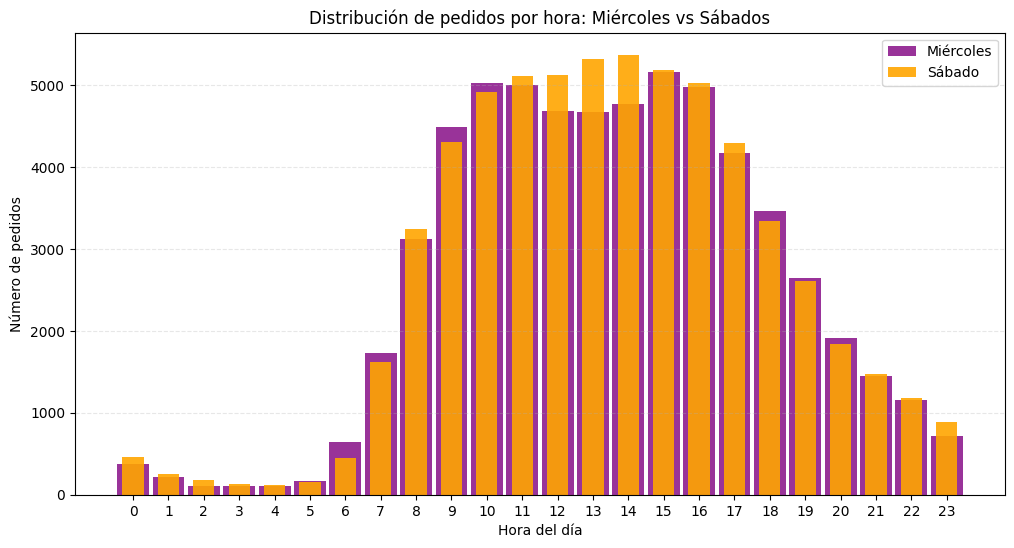

In [42]:
import matplotlib.pyplot as plt

# 1. Filtramos y preparamos los datos (esto ya lo tienes bien)
miercoles = df_orders[df_orders['order_dow'] == 3]['order_hour_of_day'].value_counts().sort_index()
sabados = df_orders[df_orders['order_dow'] == 6]['order_hour_of_day'].value_counts().sort_index()

# 2. Configuramos el gráfico de barras
plt.figure(figsize=(12, 6))

# Usamos barras con transparencia para ver dónde se solapan
plt.bar(miercoles.index, miercoles.values, alpha=0.8, width=0.9, label='Miércoles', color='purple')
plt.bar(sabados.index, sabados.values, alpha=0.9, width=0.6, label='Sábado', color='orange')

# 3. Personalización técnica
plt.title('Distribución de pedidos por hora: Miércoles vs Sábados')
plt.xlabel('Hora del día')
plt.ylabel('Número de pedidos')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

Escribe aquí tus conclusiones
Se observa que el sábado, la línea naranja, tiene un volumen ligeramente superior de pedidos durante el mediodía y la tarde, de las 12:00 hrs a las 15:00 hrs, comparado con el miércoles.
El miércoles, la línea morada, muestra una actividad un poco más temprana, hacen compras antes de la jornada laboral o durante la primera pausa.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

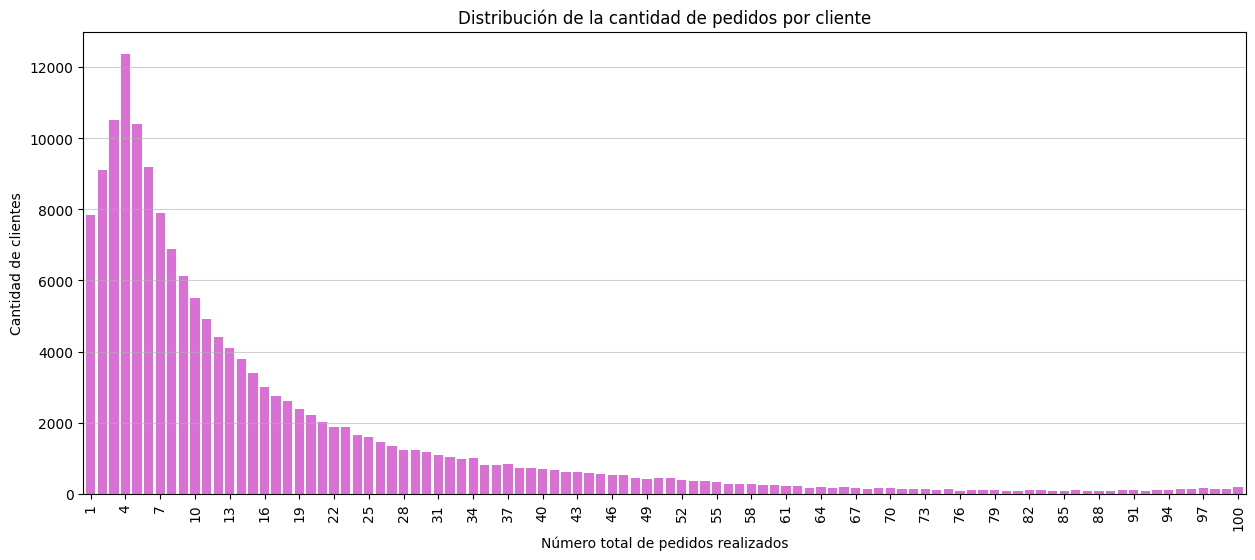

El máximo de pedidos que un solo cliente ha realizado es: 100


In [43]:
import matplotlib.pyplot as plt

# 1. Se obtiene la serie de datos 
ordenes_por_usuario = df_orders.groupby('user_id')['order_number'].max().value_counts().sort_index()

# 2. Se crea el gráfico de barras
plt.figure(figsize=(15, 6))
ordenes_por_usuario.plot(kind='bar', color='orchid', width=0.8)

# 3. Configuración de etiquetas
plt.title('Distribución de la cantidad de pedidos por cliente')
plt.xlabel('Número total de pedidos realizados')
plt.ylabel('Cantidad de clientes')

# Ajustamos los ticks de las X para que sean legibles
plt.xticks(range(0, len(ordenes_por_usuario), 3), ordenes_por_usuario.index[::3])

plt.grid(axis='y', linestyle='-', alpha=0.6)
plt.show()

print(f"El máximo de pedidos que un solo cliente ha realizado es: {df_orders.groupby('user_id')['order_number'].max().max()}")

Escribe aquí tus conclusiones
El pico más alto está en los primeros números 4 a 5 pedidos. Hay una enorme cantidad de usuarios que probaron la app pero no se convirtieron en clientes recurrentes a largo plazo.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [44]:
# 1. Se unen las tablas por la columna 'product_id'
# Se combinan ambos DataFrames por el ID y el Nombre
df_productos_nombres = df_order_products.merge(df_products[['product_id', 'product_name']], on='product_id')

# 2. Se cuentan cuántas veces aparece cada ID y nombre
# Usamos groupby para agrupar por ambas columnas y contar el número de filas
top_20_productos = df_productos_nombres.groupby(['product_id', 'product_name']).size().reset_index(name='frecuencia')

# 3. Se ordena de mayor a menor y se muestran los primeros 20
top_20_productos = top_20_productos.sort_values(by='frecuencia', ascending=False).head(20)

# Mostramos el resultado
display(top_20_productos)

,product_id,product_name,frecuencia
22310,24852,banana,66050
11767,13176,bag of organic bananas,53297
18953,21137,organic strawberries,37039
19643,21903,organic baby spinach,33971
42277,47209,organic hass avocado,29773
42778,47766,organic avocado,24689
42654,47626,large lemon,21495
15029,16797,strawberries,20018
23522,26209,limes,19690
24995,27845,organic whole milk,19600


Escribe aquí tus conclusiones
El producto más comprado es "banana", con más de 66,000 productos vendido. Es el producto ganador de la plataforma.

El usuario típico de Instacart compra principalmente frutas y verduras, realiza sus pedidos entre las 10AM y las 4PM.
Solo un grupo alcanza más de 50 pedidos.
El servicio se usa cotidianamente, porque no hay diferencia radical entre días laborales y fines de semana.

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

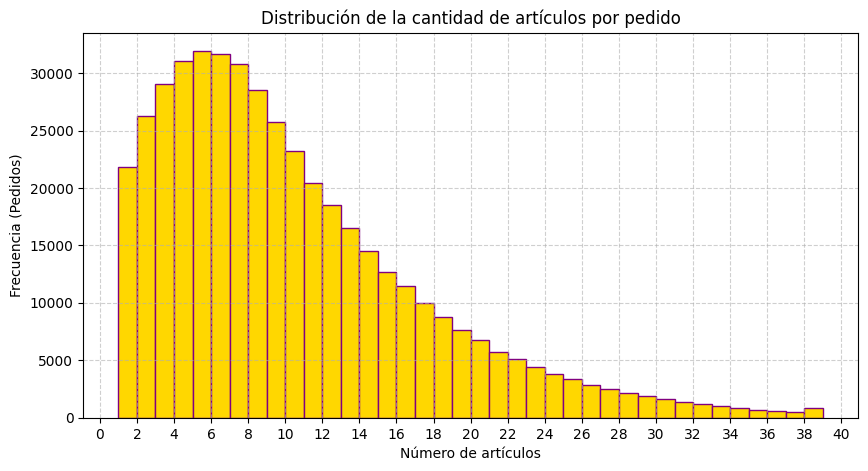

La mínima cantidad de artículos por pedido es: 1
La mediana cantidad de artículos por pedido es: 8.0
La máxima cantidad de artículos por pedido es: 127


In [45]:
# Conteo de productos por cada orden
articulos_por_pedido = df_order_products.groupby('order_id')['product_id'].count()

# Grafica de la distribución (histograma)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(articulos_por_pedido, bins=range(1, 40), color='gold', edgecolor='purple')
plt.title('Distribución de la cantidad de artículos por pedido')
plt.xlabel('Número de artículos')
plt.ylabel('Frecuencia (Pedidos)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.xticks(range(0, 41, 2))
plt.show()

print(f"La mínima cantidad de artículos por pedido es: {articulos_por_pedido.min()}")
print(f"La mediana cantidad de artículos por pedido es: {articulos_por_pedido.median()}")
print(f"La máxima cantidad de artículos por pedido es: {articulos_por_pedido.max()}")

Escribe aquí tus conclusiones
Los pedidos con mayor frecuencia varían de contener entre 1 artículo y 11 artículos, registrando 20,000 pedidos o más en la plataforma de Instacart.
De 4 a 8 artículos hay más de 30,000 pedidos, lo que quiere decir que la mayoría de los clientes compran productos en un rango de 4-8 artículos.
Posteriormente hay menos de 5,000 pedidos dentro del rango de 23-40 artículos.
El artículo ganador es la banana.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [46]:
# Se filtran re-pedidos y se unen con nombres de productos
df_reorders = df_order_products[df_order_products['reordered'] == 1]
df_reorders_nombres = df_reorders.merge(df_products[['product_id', 'product_name']], on='product_id')

# Se agrupa por ID y Nombre para mostrar ambos en el resultado
top_20_completo = df_reorders_nombres.groupby(['product_id', 'product_name']).size().sort_values(ascending=False).head(20)

print("Top 20 productos con mayor frecuencia de re-pedido (ID y Nombre):")
display(top_20_completo)

Top 20 productos con mayor frecuencia de re-pedido (ID y Nombre):


product_id  product_name            
24852       banana                      55763
13176       bag of organic bananas      44450
21137       organic strawberries        28639
21903       organic baby spinach        26233
47209       organic hass avocado        23629
47766       organic avocado             18743
27845       organic whole milk          16251
47626       large lemon                 15044
27966       organic raspberries         14748
16797       strawberries                13945
26209       limes                       13327
22935       organic yellow onion        11145
24964       organic garlic              10411
45007       organic zucchini            10076
49683       cucumber kirby               9538
28204       organic fuji apple           8989
8277        apple honeycrisp organic     8836
39275       organic blueberries          8799
5876        organic lemon                8412
49235       organic half & half          8389
dtype: int64

Escribe aquí tus conclusiones
Los clientes de Instacart consumen en su mayoría banana y bananas orgánicas.

A excepción de la leche half & half, todos los productos del top 20 son frutas frescas.
Sobresaliendo el consumo de la banana en sus dos presentaciones.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [47]:
# Como 'reordered' es 1 (sí) o 0 (no), la media da directamente la proporción
tasa_repeticion = df_order_products.groupby('product_id')['reordered'].mean().reset_index()

# Se une la tasa con la tabla de productos para saber los nombres
tasa_repeticion = tasa_repeticion.merge(df_products[['product_id', 'product_name']], on='product_id')

# Se renombran las columnas para que sea claro
tasa_repeticion.columns = ['product_id', 'reorder_rate', 'product_name']

# Se consideran productos que tengan un volumen mínimo de ventas (ej. > 50 veces)
# para evitar que un producto vendido 1 sola vez y repetido 1 vez tenga error de conteo.
conteo_productos = df_order_products['product_id'].value_counts().reset_index()
conteo_productos.columns = ['product_id', 'total_pedidos']

tasa_final = tasa_repeticion.merge(conteo_productos, on='product_id')
top_repeticion = tasa_final[tasa_final['total_pedidos'] > 50].sort_values(by='reorder_rate', ascending=False).head(20)
top=tasa_final[tasa_final['total_pedidos'] > 50].sort_values(by='reorder_rate', ascending=False)
print(top)
display(top_repeticion[['product_id','product_name', 'reorder_rate']])


       product_id  reorder_rate                             product_name  \
43029       48041      0.907692  danactive vanilla probiotic dairy drink   
29586       32978      0.893939                       lemon lime seltzer   
35644       39782      0.892308      organic raspberry mate energy drink   
15637       17469      0.888889                     lo-carb energy drink   
22442       25000      0.886792         whole wheat multigrain pop cakes   
...           ...           ...                                      ...   
5643         6288      0.021053                            ground cloves   
33288       37120      0.018349                                dill weed   
25791       28741      0.018182                    organic ground cloves   
13140       14688      0.018182                           bamboo skewers   
39958       44626      0.010989                          ground allspice   

       total_pedidos  
43029             65  
29586             66  
35644             

,product_id,product_name,reorder_rate
43029,48041,danactive vanilla probiotic dairy drink,0.907692
29586,32978,lemon lime seltzer,0.893939
35644,39782,organic raspberry mate energy drink,0.892308
15637,17469,lo-carb energy drink,0.888889
22442,25000,whole wheat multigrain pop cakes,0.886792
43074,48095,purified water- 9.5ph+,0.877193
8318,9292,half and half ultra pasteurized,0.876574
2412,2677,yerba mate sparkling classic gold,0.871345
42297,47231,ultra-purified water,0.868293
1032,1157,wheat sandwich bread,0.863946


Escribe aquí tus conclusiones
Los productos con mayor tasa de repetición suelen ser lácteos y agua mineral. Son productos que se consumen diario y se terminan rápido, no son los más vendidos en volumen total, pero sí los que el cliente vuelve a comprar más.
Un valor arriba del 0.85% significa que el 85% de las veces que el producto entra en el carrito, es porque el cliente ya lo conocía y lo quería de nuevo.
Los productos más importantes para Instacart son los que cuentan con mayor porcentaje de re-compra. 
Porque son los productos que el cliente normalmente busca en la aplicación, por lo que hay que tener un inventario que abarque la demanda del cliente para seguir abasteciendo el consumo. 

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

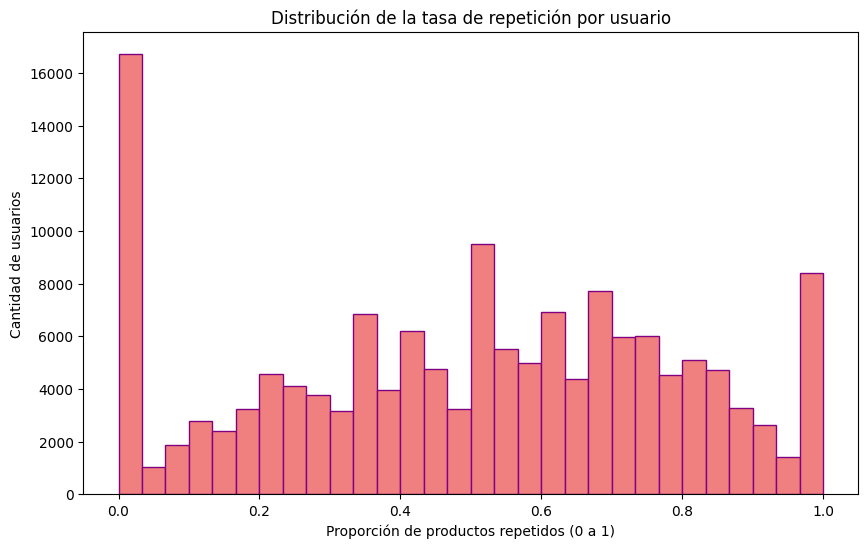

,user_id,user_reorder_ratio
0,2,0.038462
1,4,0.000000
2,5,0.666667
3,6,0.000000
4,7,0.928571
...,...,...
149621,206203,0.222222
149622,206206,0.714286
149623,206207,0.891304
149624,206208,0.696000


Resumen numérico de la proporción de reorden o reincidencia por usuario y cuantiles clave:
count    149626.000000
mean          0.494853
std           0.292685
min           0.000000
25%           0.272727
50%           0.500000
75%           0.724138
max           1.000000
Name: user_reorder_ratio, dtype: float64


In [53]:
# 1. Se une df_orders con df_order_products para tener el 'user_id' junto al campo 'reordered'
df_merged_user_reorder = df_order_products.merge(df_orders[['order_id', 'user_id']], on='order_id')

# 2. Se agrupa por usuario y calculamos la media de 'reordered'
# Esto nos da la proporción de productos repetidos por cada cliente
tasa_repeticion_usuario = df_merged_user_reorder.groupby('user_id')['reordered'].mean().reset_index()

# 3. Se renombran columnas para mayor claridad
tasa_repeticion_usuario.columns = ['user_id', 'user_reorder_ratio']

# 4. Para las conclusiones, veamos la distribución de estas tasas
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(tasa_repeticion_usuario['user_reorder_ratio'], bins=30, color='lightcoral', edgecolor='purple')
plt.title('Distribución de la tasa de repetición por usuario')
plt.xlabel('Proporción de productos repetidos (0 a 1)')
plt.ylabel('Cantidad de usuarios')
plt.show()

# Se muestran los resultados
display(tasa_repeticion_usuario)

# Sugerencia .describe()
resumen_stats = tasa_repeticion_usuario['user_reorder_ratio'].describe()

print("Resumen numérico de la proporción de reorden o reincidencia por usuario y cuantiles clave:")
print(resumen_stats)



Escribe aquí tus conclusiones

El pico en 0.0 representa a los clientes nuevos en su primera compra, mientras que el resto de la población muestra una tendencia a repetir entre el 40% y 60% de sus artículos. Existe un grupo considerable de usuarios de hábito, cerca del 1.0 que utilizan la plataforma exclusivamente para reposición de productos ya conocidos, lo que confirma que Instacart se ha consolidado como una herramienta de rutina diaria para una parte importante de su base de usuarios.
La tabla nos enseña la cantidad de productos que son repetidos dentro del carrito.
Los usuarios con proporción 1.0 significa que lo que tienen en su carrito ya lo habían tenido antes en su carrito, por lo que están repitiendo nuevamente las compras dentro de Instacart. Comprando los mismos productos.
Entre más se acerca al 1.0, la reincidencia de recompra del cliente es mayor, por lo que son considerados clientes más fieles a los productos del catálogo y a Instacart.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [54]:
# Filtro de los primeros productos en añadirse
first_choice = df_order_products[df_order_products['add_to_cart_order'] == 1]
top_20_first = first_choice.merge(df_products, on='product_id')

resultado_c5 = (top_20_first
                .groupby(['product_id', 'product_name'])
                .size()
                .reset_index(name='veces_primero')
                .sort_values(by='veces_primero', ascending=False)
                .head(20)
                .reset_index(drop=True))

# Tabla limpia
display(resultado_c5)

,product_id,product_name,veces_primero
0,24852,banana,15562
1,13176,bag of organic bananas,11026
2,27845,organic whole milk,4363
3,21137,organic strawberries,3946
4,47209,organic hass avocado,3390
5,21903,organic baby spinach,3336
6,47766,organic avocado,3044
7,19660,spring water,2336
8,16797,strawberries,2308
9,27966,organic raspberries,2024


Escribe aquí tus conclusiones
Si leemos el top 20 de los principales artículos que las personas ponen primero en sus carritos.
Se lee claramente el órden del consumo de las personas en el listado. 
Por lo que la mayoría compra en principio bananas y bolsa de bananas orgánicas. 
En esos dos productos, inclusive de forma individual las bananas están más de 2 veces primero que sus productos siguientes.
La leche orgánica, las fresas orgánicas y el aguacate hass. 
Los demás productos están muy por debajo en comparación con las bananas y la bolsa de bananas orgánicas.
Las frambuesas, por ejemplo, están casi 10 veces menos primero que la bolsa de bananas orgánicas. 
Por lo que el producto que se consume de primera mano es la banana, en relación con el consumo de todos los clientes.

### Conclusion general del proyecto:

El análisis revela un ecosistema basado en la recurrencia. La alta frecuencia de pedidos cada 7 días, 
sumada a una tasa de repetición equilibrada (50% recurrente, 50% nuevo), posiciona a Instacart como una herramienta de hábito doméstico. 
El éxito del catálogo depende de los productos frescos y orgánicos, que actúan como la puerta de entrada para la mayoría de las transacciones.